# Lab 4: Regression Analysis with Regularization Techniques

**Name:** Pawan Sharma
**Course:** Advanced Big Data and Data Mining (MSCS-634-M50)
**Assignment:** Lab 4 – Regression Analysis with Regularization Techniques

In this lab I work through simple linear, multiple, and polynomial regression on the sklearn Diabetes dataset, then add Ridge and Lasso regularization to see how they deal with overfitting. Every model is scored with MAE, MSE, RMSE, and R² on the same held-out test set so the comparison at the end is fair.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Step 1: Data Preparation

### 1.1 Load the dataset

In [2]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()

print("Shape:", df.shape)
df.head()

Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
print(diabetes.DESCR[:1500])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

The dataset has 442 patients and 10 baseline features (age, sex, BMI, average blood pressure, and six blood serum measurements `s1`–`s6`). The target is a quantitative measure of disease progression one year after baseline.

One thing worth noting: sklearn ships these features already mean-centered and scaled (each column is divided by the standard deviation times the square root of the number of samples), so the raw values look tiny. That matters later because Ridge and Lasso are sensitive to feature scale.

### 1.2 Explore features, target, and distributions

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [5]:
df.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.0000,0.0476,-0.1072,-0.0373,0.0054,0.0381,0.1107
sex,442.0,0.0000,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507
bmi,442.0,-0.0000,0.0476,-0.0903,-0.0342,-0.0073,0.0312,0.1706
bp,442.0,-0.0000,0.0476,-0.1124,-0.0367,-0.0057,0.0356,0.1320
s1,442.0,-0.0000,0.0476,-0.1268,-0.0342,-0.0043,0.0284,0.1539
s2,442.0,0.0000,0.0476,-0.1156,-0.0304,-0.0038,0.0298,0.1988
s3,442.0,-0.0000,0.0476,-0.1023,-0.0351,-0.0066,0.0293,0.1812
s4,442.0,-0.0000,0.0476,-0.0764,-0.0395,-0.0026,0.0343,0.1852
s5,442.0,0.0000,0.0476,-0.1261,-0.0332,-0.0019,0.0324,0.1336
s6,442.0,0.0000,0.0476,-0.1378,-0.0332,-0.0011,0.0279,0.1356


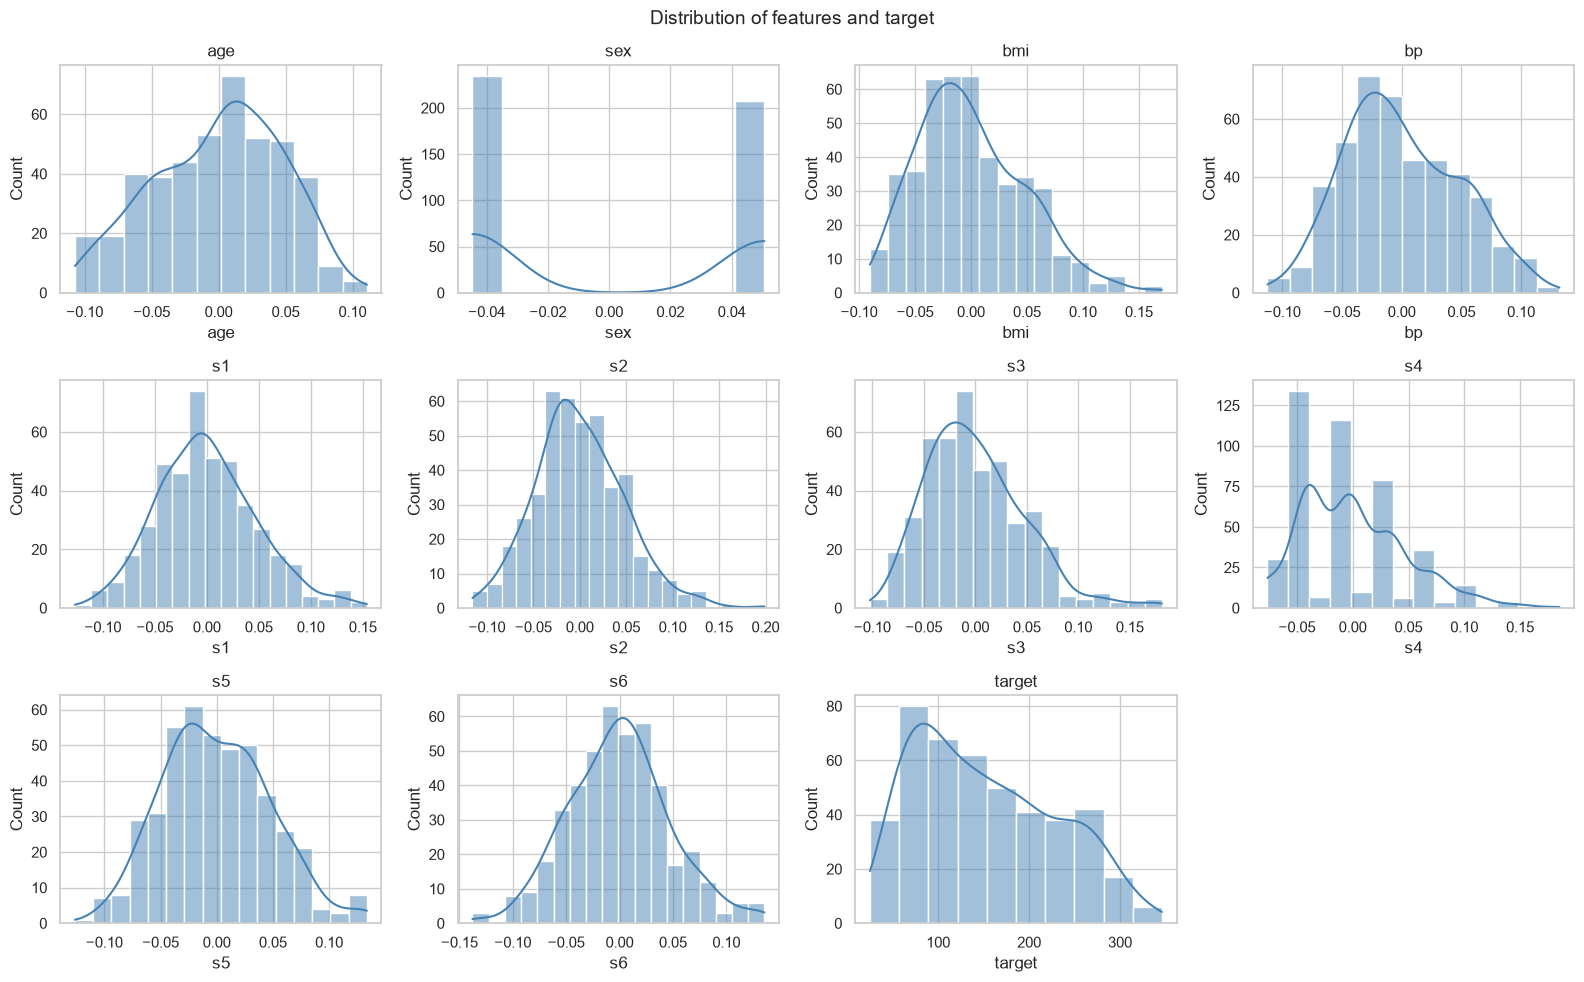

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.suptitle("Distribution of features and target", fontsize=14)
plt.tight_layout()
plt.show()

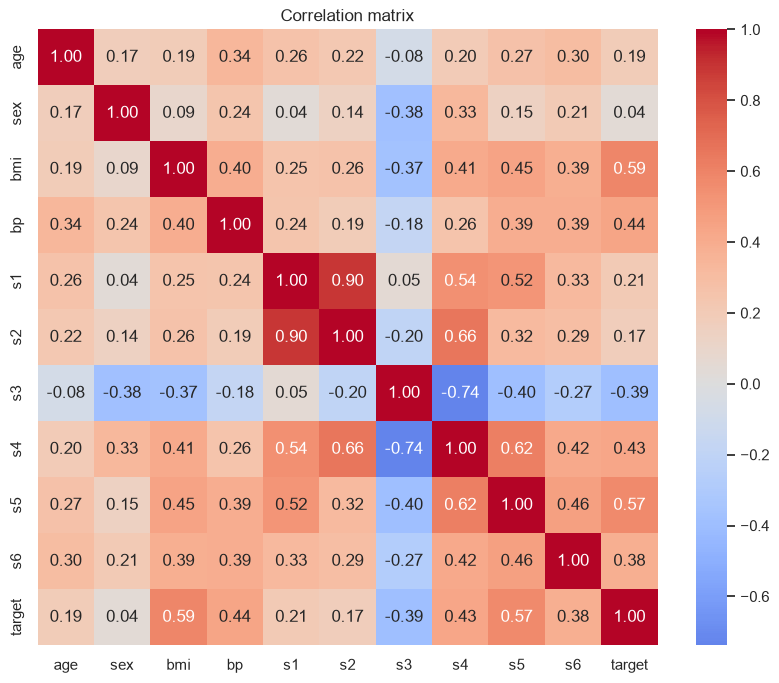

Correlation of each feature with the target:
bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: target, dtype: float64


In [7]:
plt.figure(figsize=(10, 8))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print("Correlation of each feature with the target:")
print(corr["target"].drop("target").sort_values(ascending=False).round(3))

From the correlation matrix, `bmi` (0.59) and `s5` (0.57) have the strongest relationship with the target, followed by `bp` and `s4`. `s3` is the only notable negative correlation. I also see that `s1` and `s2` are very highly correlated with each other (around 0.90), which is a multicollinearity problem that should make Ridge regression useful later.

The target itself is right-skewed and ranges from 25 to 346.

### 1.3 Data cleaning

In [8]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate rows: 0


There are no missing values and no duplicate rows, so no imputation or row removal is needed. The features are already scaled by sklearn, so I'm leaving them as they are. I still wrap the polynomial and regularized models in a `StandardScaler` pipeline because polynomial terms of already-small numbers get even smaller, and the penalty in Ridge/Lasso should treat every term on the same scale.

### 1.4 Train/test split

I use one 80/20 split with a fixed random state and reuse it for every model so the metrics are directly comparable.

In [9]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (353, 10)  Test: (89, 10)


In [10]:
results = []

def evaluate(name, y_true, y_pred, store=True):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    if store:
        results.append({"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2})
    print(f"{name}\n  MAE: {mae:.2f}  MSE: {mse:.2f}  RMSE: {rmse:.2f}  R²: {r2:.4f}")
    return mae, mse, rmse, r2

def plot_actual_vs_pred(y_true, y_pred, title, ax=None, color="teal"):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(y_true, y_pred, alpha=0.7, color=color, edgecolor="k", linewidth=0.3)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_xlabel("Actual disease progression")
    ax.set_ylabel("Predicted disease progression")
    ax.set_title(title)
    ax.legend()
    return ax

## Step 2: Simple Linear Regression

For the single-feature model I picked `bmi` because it has the highest correlation with the target.

In [11]:
X_train_bmi = X_train[["bmi"]]
X_test_bmi = X_test[["bmi"]]

slr = LinearRegression()
slr.fit(X_train_bmi, y_train)
y_pred_slr = slr.predict(X_test_bmi)

print(f"Intercept: {slr.intercept_:.2f}   Slope (bmi): {slr.coef_[0]:.2f}\n")
_ = evaluate("Simple Linear (BMI)", y_test, y_pred_slr)

Intercept: 152.00   Slope (bmi): 998.58

Simple Linear (BMI)
  MAE: 52.26  MSE: 4061.83  RMSE: 63.73  R²: 0.2334


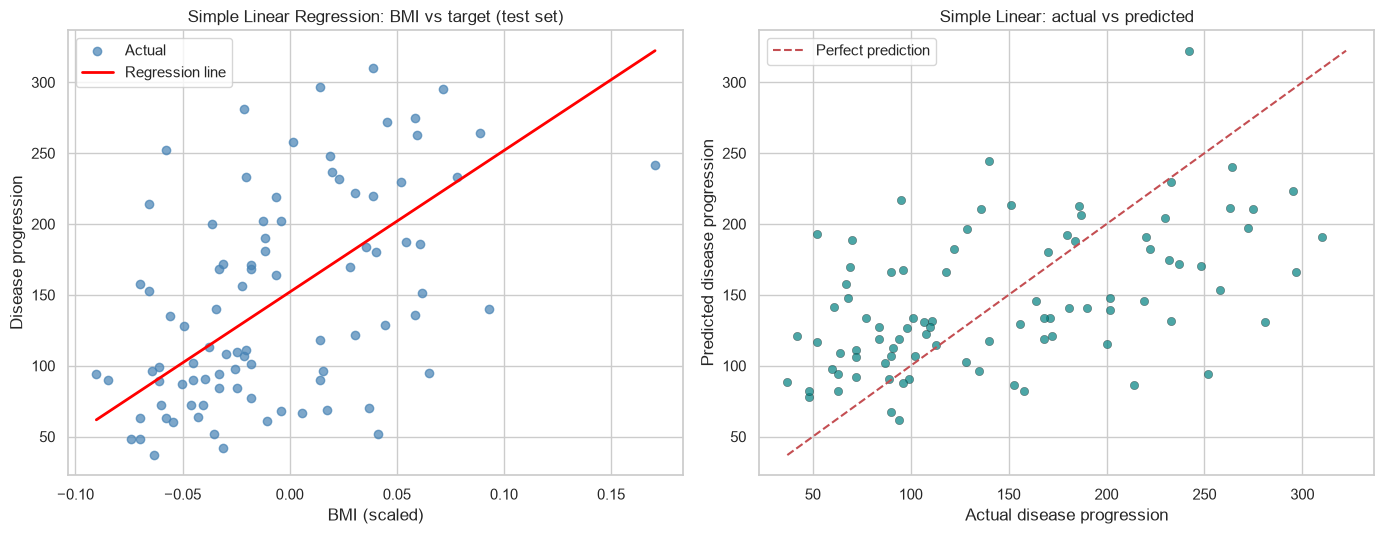

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

order = np.argsort(X_test_bmi["bmi"].values)
axes[0].scatter(X_test_bmi, y_test, alpha=0.7, label="Actual", color="steelblue")
axes[0].plot(X_test_bmi.values[order], y_pred_slr[order], color="red", linewidth=2, label="Regression line")
axes[0].set_xlabel("BMI (scaled)")
axes[0].set_ylabel("Disease progression")
axes[0].set_title("Simple Linear Regression: BMI vs target (test set)")
axes[0].legend()

plot_actual_vs_pred(y_test, y_pred_slr, "Simple Linear: actual vs predicted", ax=axes[1])
plt.tight_layout()
plt.show()

BMI on its own explains roughly a quarter of the variance in disease progression on the test set. The line captures the overall upward trend, but the points are widely scattered around it, which tells me one feature isn't enough to model this target well.

## Step 3: Multiple Regression

Now I use all 10 features.

In [13]:
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred_mlr = mlr.predict(X_test)

evaluate("Multiple Linear (all features)", y_test, y_pred_mlr)

coef_df = pd.Series(mlr.coef_, index=X.columns).sort_values()
print("\nCoefficients:")
print(coef_df.round(2))

Multiple Linear (all features)
  MAE: 42.79  MSE: 2900.19  RMSE: 53.85  R²: 0.4526

Coefficients:
s1    -931.49
sex   -241.96
age     37.90
s6      48.67
s3     163.42
s4     275.32
bp     347.70
s2     518.06
bmi    542.43
s5     736.20
dtype: float64


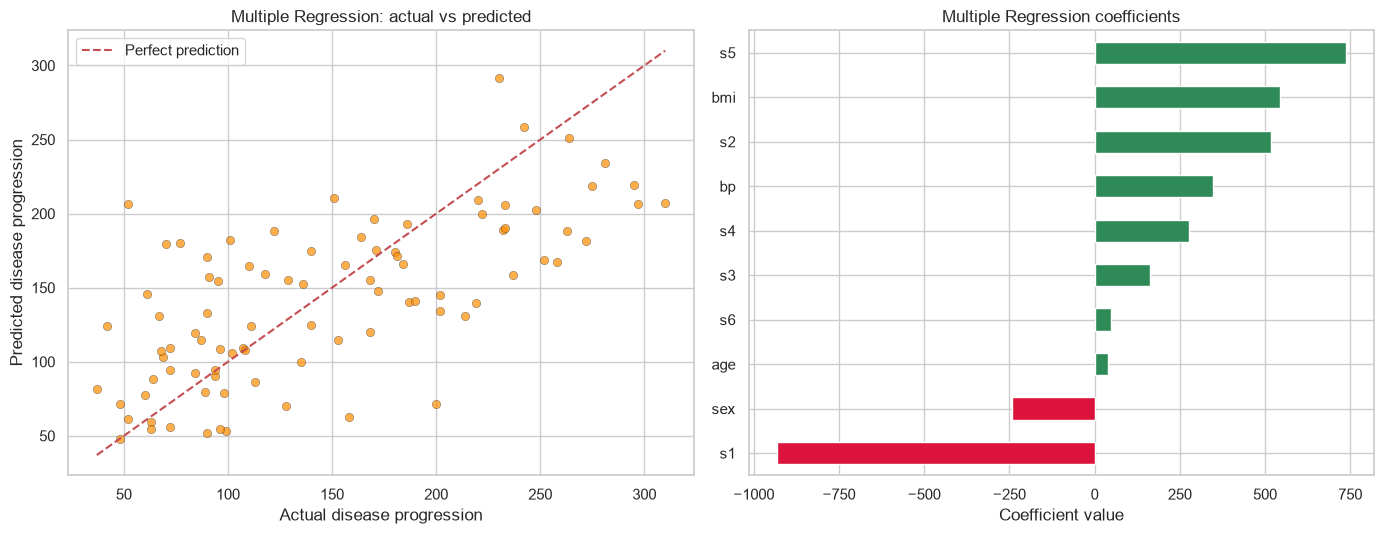

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_actual_vs_pred(y_test, y_pred_mlr, "Multiple Regression: actual vs predicted", ax=axes[0], color="darkorange")

coef_df.plot(kind="barh", ax=axes[1], color=["crimson" if c < 0 else "seagreen" for c in coef_df])
axes[1].set_title("Multiple Regression coefficients")
axes[1].set_xlabel("Coefficient value")
plt.tight_layout()
plt.show()

Using all features lifts R² noticeably over the BMI-only model and cuts the error. The points now hug the diagonal more closely.

The coefficients are interesting: `s1` and `s2` come out with very large values of opposite sign. Since those two features are about 0.90 correlated, the model is essentially letting them cancel each other out. That's a classic sign of multicollinearity, and it's exactly the kind of instability Ridge regression is meant to fix.

## Step 4: Polynomial Regression

### 4.1 Polynomial regression on all features (degree 2)

I add squared terms and pairwise interaction terms for all 10 features. That expands the input from 10 columns to 65.

In [15]:
poly2 = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression()
)
poly2.fit(X_train, y_train)
y_pred_poly2 = poly2.predict(X_test)

n_terms = poly2.named_steps["polynomialfeatures"].n_output_features_
print(f"Number of polynomial features: {n_terms}\n")

r2_train_poly2 = r2_score(y_train, poly2.predict(X_train))
print(f"Train R²: {r2_train_poly2:.4f}")
_ = evaluate("Polynomial deg 2 (all features)", y_test, y_pred_poly2)

Number of polynomial features: 65

Train R²: 0.6062
Polynomial deg 2 (all features)
  MAE: 43.58  MSE: 3096.03  RMSE: 55.64  R²: 0.4156


The training R² goes up compared to plain multiple regression, but the test R² drops. With 65 terms and only 353 training rows, the model is starting to fit noise in the training data. This is the first sign of overfitting.

### 4.2 How polynomial degree affects underfitting and overfitting

To show the effect clearly, I go back to the single BMI feature and increase the degree from 1 to 15. A single feature makes the curve easy to see.

In [16]:
degrees = range(1, 16)
train_scores, test_scores, train_rmse, test_rmse = [], [], [], []

for d in degrees:
    m = make_pipeline(PolynomialFeatures(degree=d, include_bias=False), StandardScaler(), LinearRegression())
    m.fit(X_train_bmi, y_train)
    p_tr, p_te = m.predict(X_train_bmi), m.predict(X_test_bmi)
    train_scores.append(r2_score(y_train, p_tr))
    test_scores.append(r2_score(y_test, p_te))
    train_rmse.append(np.sqrt(mean_squared_error(y_train, p_tr)))
    test_rmse.append(np.sqrt(mean_squared_error(y_test, p_te)))

deg_df = pd.DataFrame({"Degree": list(degrees), "Train R²": train_scores, "Test R²": test_scores,
                       "Train RMSE": train_rmse, "Test RMSE": test_rmse}).round(4)
deg_df

,Degree,Train R²,Test R²,Train RMSE,Test RMSE
0,1,0.3657,0.2334,62.0815,63.7325
1,2,0.3665,0.2290,62.0430,63.9142
2,3,0.3667,0.2329,62.0359,63.7530
3,4,0.3695,0.2023,61.8955,65.0088
4,5,0.3707,0.2288,61.8366,63.9206
5,6,0.3721,0.2489,61.7682,63.0839
6,7,0.3740,0.2086,61.6754,64.7541
7,8,0.3853,-0.4864,61.1159,88.7430
8,9,0.3853,-0.3600,61.1137,84.8842
9,10,0.3870,0.1855,61.0296,65.6927


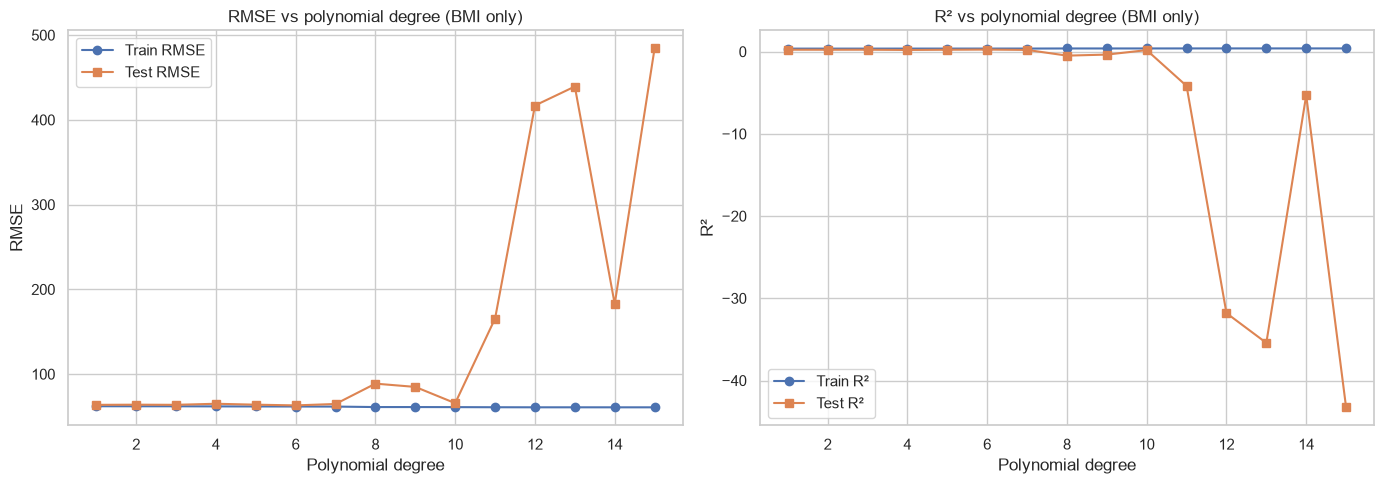

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(degrees, train_rmse, "o-", label="Train RMSE")
axes[0].plot(degrees, test_rmse, "s-", label="Test RMSE")
axes[0].set_xlabel("Polynomial degree")
axes[0].set_ylabel("RMSE")
axes[0].set_title("RMSE vs polynomial degree (BMI only)")
axes[0].legend()

axes[1].plot(degrees, train_scores, "o-", label="Train R²")
axes[1].plot(degrees, test_scores, "s-", label="Test R²")
axes[1].set_xlabel("Polynomial degree")
axes[1].set_ylabel("R²")
axes[1].set_title("R² vs polynomial degree (BMI only)")
axes[1].legend()
plt.tight_layout()
plt.show()

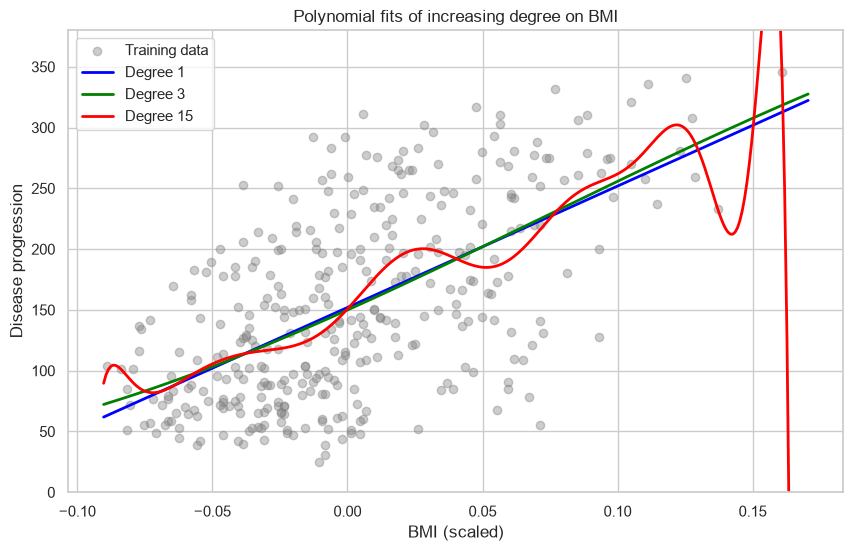

In [18]:
x_grid = pd.DataFrame({"bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 300)})
plt.figure(figsize=(10, 6))
plt.scatter(X_train_bmi, y_train, alpha=0.4, color="gray", label="Training data")
for d, c in zip([1, 3, 15], ["blue", "green", "red"]):
    m = make_pipeline(PolynomialFeatures(degree=d, include_bias=False), StandardScaler(), LinearRegression())
    m.fit(X_train_bmi, y_train)
    plt.plot(x_grid, m.predict(x_grid), color=c, linewidth=2, label=f"Degree {d}")
plt.ylim(0, 380)
plt.xlabel("BMI (scaled)")
plt.ylabel("Disease progression")
plt.title("Polynomial fits of increasing degree on BMI")
plt.legend()
plt.show()

In [19]:
# Keep the best single-feature polynomial for the final comparison
best_deg = int(deg_df.loc[deg_df["Test R²"].idxmax(), "Degree"])
poly_bmi = make_pipeline(PolynomialFeatures(degree=best_deg, include_bias=False), StandardScaler(), LinearRegression())
poly_bmi.fit(X_train_bmi, y_train)
y_pred_poly_bmi = poly_bmi.predict(X_test_bmi)
_ = evaluate(f"Polynomial deg {best_deg} (BMI)", y_test, y_pred_poly_bmi)

Polynomial deg 6 (BMI)
  MAE: 51.12  MSE: 3979.58  RMSE: 63.08  R²: 0.2489


The degree experiment shows the trade-off pretty clearly:

* **Low degree (1–3):** train and test errors stay close together (test RMSE around 63.7). Since the BMI–target relationship is mostly linear, a straight line is about as good as it gets with one feature. The model is underfitting overall, but that's because it only sees one feature, not because the degree is too low.
* **Middle degrees (4–7):** training R² creeps up a little each time, but test R² bounces around between about 0.20 and 0.25. The extra flexibility isn't capturing anything real.
* **High degree (8+):** this is clear overfitting. Training RMSE keeps falling, but test RMSE explodes (over 400 at degrees 12–15) and test R² goes deeply negative, which means the model is worse than just predicting the average. The degree-15 curve swings wildly near the edges of the BMI range, where a few training points pull it around and the test points fall outside what it learned.

Degree 6 happened to score best on the test set (R² 0.249 vs 0.233 for the straight line), but with test scores this noisy I wouldn't read much into that small gain. Compared to the earlier models, the degree-2 model on all features also did worse than plain multiple regression on the test set (0.416 vs 0.453) even though it fit the training data better (0.606 vs roughly 0.53). For this dataset, adding polynomial terms doesn't pay off unless something controls the extra complexity, which is where regularization comes in.

## Step 5: Regularization with Ridge and Lasso

* **Ridge (L2)** adds a penalty proportional to the sum of squared coefficients. It shrinks all coefficients toward zero but never makes them exactly zero. It handles correlated features well.
* **Lasso (L1)** adds a penalty proportional to the sum of absolute coefficient values. It can push coefficients exactly to zero, so it does feature selection.

The strength of the penalty is controlled by `alpha`. `alpha = 0` is ordinary least squares; larger values shrink coefficients more.

I apply both to (a) the 10 original features and (b) the 65-term degree-2 polynomial features, since the polynomial model is the one that overfit.

### 5.1 Effect of alpha

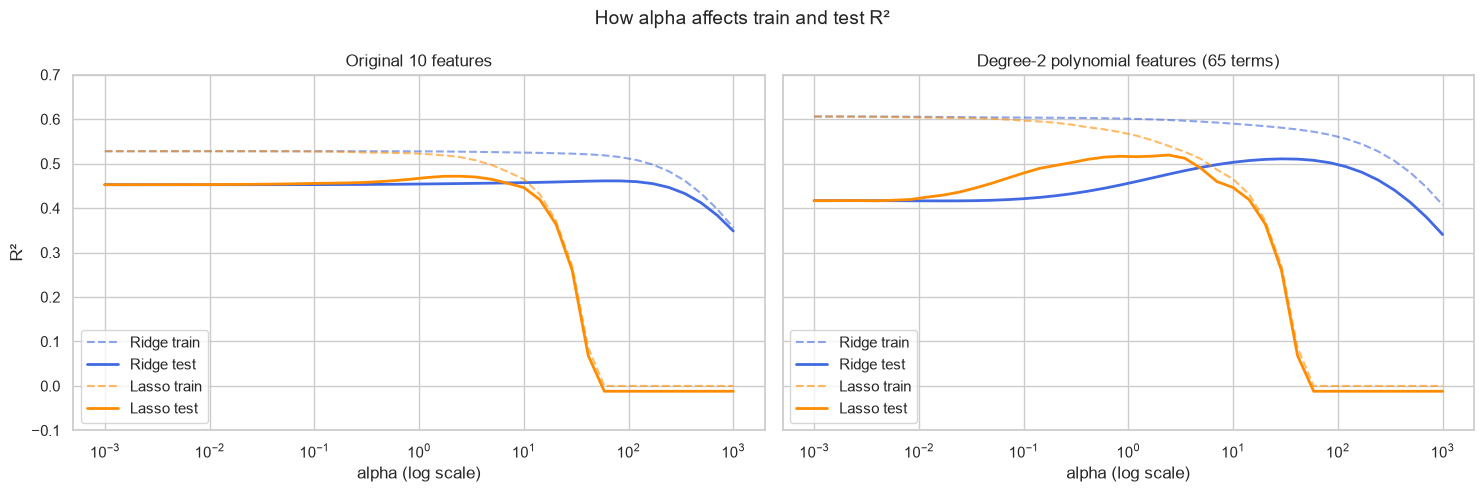

Ridge degree 1: best alpha = 58.7802, test R² = 0.4612
Ridge degree 2: best alpha = 28.9427, test R² = 0.5107
Lasso degree 1: best alpha = 2.4245, test R² = 0.4717
Lasso degree 2: best alpha = 2.4245, test R² = 0.5194


In [20]:
alphas = np.logspace(-3, 3, 40)

def alpha_sweep(model_cls, degree):
    tr, te = [], []
    for a in alphas:
        steps = []
        if degree > 1:
            steps.append(PolynomialFeatures(degree=degree, include_bias=False))
        steps += [StandardScaler(), model_cls(alpha=a, max_iter=50000)]
        m = make_pipeline(*steps).fit(X_train, y_train)
        tr.append(r2_score(y_train, m.predict(X_train)))
        te.append(r2_score(y_test, m.predict(X_test)))
    return np.array(tr), np.array(te)

sweeps = {}
for name, cls in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for deg in [1, 2]:
        sweeps[(name, deg)] = alpha_sweep(cls, deg)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, deg in zip(axes, [1, 2]):
    for name, c in [("Ridge", "royalblue"), ("Lasso", "darkorange")]:
        tr, te = sweeps[(name, deg)]
        ax.semilogx(alphas, tr, "--", color=c, alpha=0.6, label=f"{name} train")
        ax.semilogx(alphas, te, "-", color=c, linewidth=2, label=f"{name} test")
    ax.set_xlabel("alpha (log scale)")
    ax.set_title("Original 10 features" if deg == 1 else "Degree-2 polynomial features (65 terms)")
    ax.legend()
axes[0].set_ylabel("R²")
axes[0].set_ylim(-0.1, 0.7)
plt.suptitle("How alpha affects train and test R²", fontsize=14)
plt.tight_layout()
plt.show()

best_alpha = {}
for k, (tr, te) in sweeps.items():
    i = te.argmax()
    best_alpha[k] = alphas[i]
    print(f"{k[0]:5s} degree {k[1]}: best alpha = {alphas[i]:.4f}, test R² = {te[i]:.4f}")

Note: I'm choosing alpha by looking at the test curve here to illustrate its effect. In section 5.4 I confirm the choice with 5-fold cross-validation on the training data only, which is the honest way to tune it.

What the curves show:

* **Very small alpha:** both models behave like ordinary least squares. On the polynomial features, there's a big gap between train and test R², i.e. overfitting.
* **Moderate alpha:** the training R² drops a little but the test R² rises. The penalty is trading a bit of bias for a lot less variance. This is the sweet spot.
* **Very large alpha:** coefficients are crushed toward zero and both train and test R² collapse. The model underfits. Lasso hits this wall sooner because once alpha is large enough it zeros out every coefficient and just predicts the mean.

### 5.2 Fit the final Ridge and Lasso models

In [21]:
def build(model_cls, alpha, degree):
    steps = []
    if degree > 1:
        steps.append(PolynomialFeatures(degree=degree, include_bias=False))
    steps += [StandardScaler(), model_cls(alpha=alpha, max_iter=50000)]
    return make_pipeline(*steps).fit(X_train, y_train)

final = {}
for (name, deg), a in best_alpha.items():
    cls = Ridge if name == "Ridge" else Lasso
    m = build(cls, a, deg)
    label = f"{name} (α={a:.3g})" if deg == 1 else f"{name} poly deg 2 (α={a:.3g})"
    pred = m.predict(X_test)
    final[(name, deg)] = (m, pred)
    print(f"Train R²: {r2_score(y_train, m.predict(X_train)):.4f}")
    evaluate(label, y_test, pred)
    print()

Train R²: 0.5186
Ridge (α=58.8)
  MAE: 43.07  MSE: 2854.45  RMSE: 53.43  R²: 0.4612

Train R²: 0.5808
Ridge poly deg 2 (α=28.9)
  MAE: 40.04  MSE: 2592.19  RMSE: 50.91  R²: 0.5107

Train R²: 0.5151
Lasso (α=2.42)
  MAE: 42.91  MSE: 2798.87  RMSE: 52.90  R²: 0.4717

Train R²: 0.5398
Lasso poly deg 2 (α=2.42)
  MAE: 40.83  MSE: 2546.54  RMSE: 50.46  R²: 0.5194



### 5.3 Visualizing Ridge vs Lasso

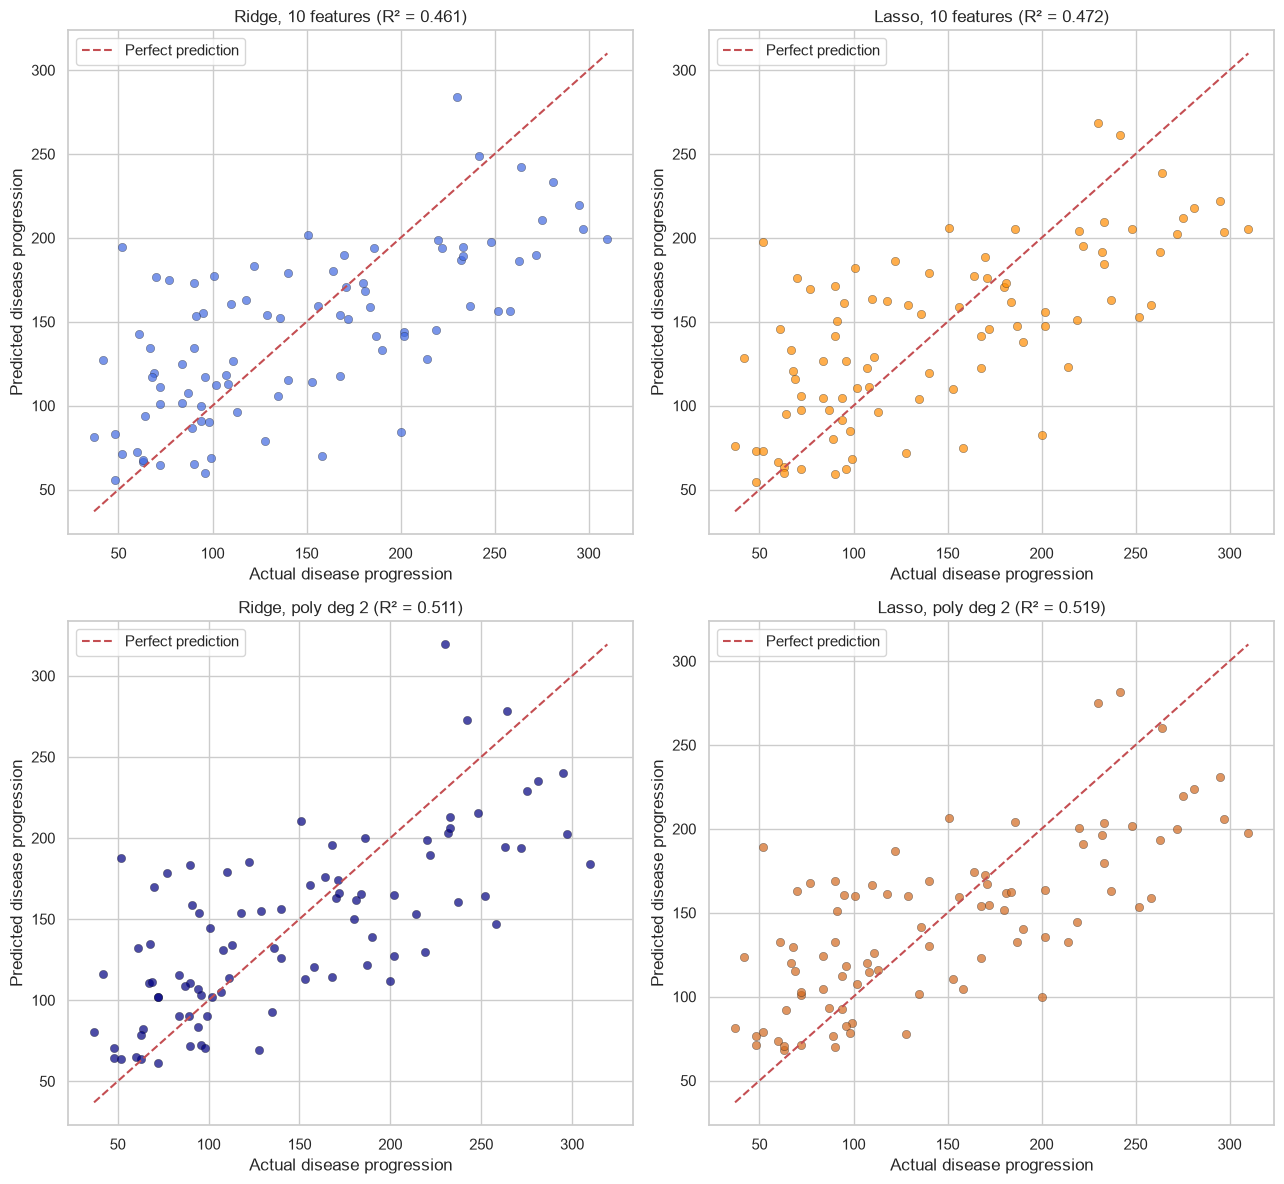

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 12))
for ax, (key, color) in zip(axes.flat, [(("Ridge", 1), "royalblue"), (("Lasso", 1), "darkorange"),
                                       (("Ridge", 2), "navy"), (("Lasso", 2), "chocolate")]):
    name, deg = key
    feat = "10 features" if deg == 1 else "poly deg 2"
    r2 = r2_score(y_test, final[key][1])
    plot_actual_vs_pred(y_test, final[key][1], f"{name}, {feat} (R² = {r2:.3f})", ax=ax, color=color)
plt.tight_layout()
plt.show()

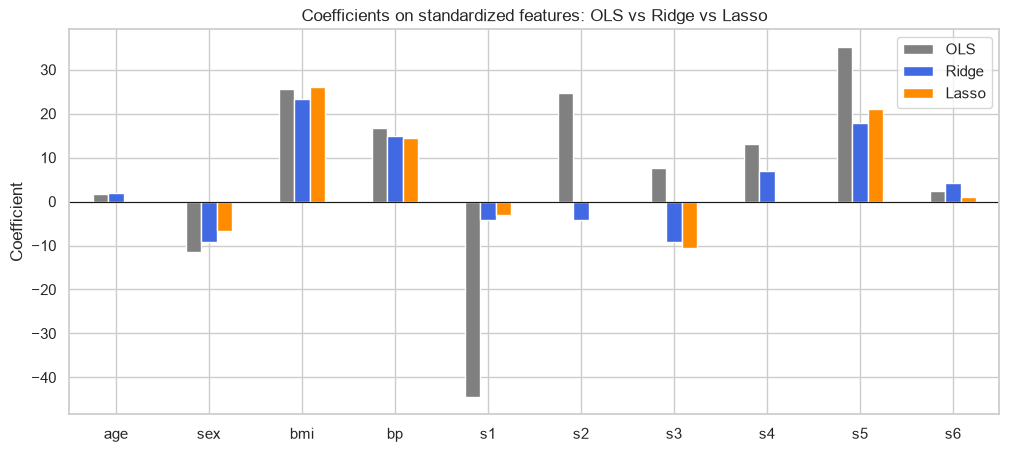

,OLS,Ridge,Lasso
age,1.75,2.04,0.00
sex,-11.51,-9.30,-6.74
bmi,25.61,23.25,26.09
bp,16.83,14.88,14.36
s1,-44.45,-4.23,-3.16
s2,24.64,-4.30,-0.00
s3,7.68,-9.15,-10.62
s4,13.14,6.99,0.00
s5,35.16,17.97,20.94
s6,2.35,4.13,1.13


In [23]:
ridge_coefs = final[("Ridge", 1)][0][-1].coef_
lasso_coefs = final[("Lasso", 1)][0][-1].coef_
ols_coefs = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)[-1].coef_

coef_compare = pd.DataFrame({"OLS": ols_coefs, "Ridge": ridge_coefs, "Lasso": lasso_coefs}, index=X.columns)
coef_compare.plot(kind="bar", figsize=(12, 5), color=["gray", "royalblue", "darkorange"])
plt.axhline(0, color="k", linewidth=0.8)
plt.title("Coefficients on standardized features: OLS vs Ridge vs Lasso")
plt.ylabel("Coefficient")
plt.xticks(rotation=0)
plt.show()

coef_compare.round(2)

In [ ]:
# Coefficient paths: how each coefficient shrinks as alpha grows
path_alphas = np.logspace(-2, 2.5, 60)
Xs_train = StandardScaler().fit_transform(X_train)
ridge_path = np.array([Ridge(alpha=a).fit(Xs_train, y_train).coef_ for a in np.logspace(-2, 4, 60)])
lasso_path = np.array([Lasso(alpha=a, max_iter=50000).fit(Xs_train, y_train).coef_ for a in path_alphas])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for i, col in enumerate(X.columns):
    axes[0].semilogx(np.logspace(-2, 4, 60), ridge_path[:, i], label=col)
    axes[1].semilogx(path_alphas, lasso_path[:, i], label=col)
axes[0].set_title("Ridge coefficient paths")
axes[1].set_title("Lasso coefficient paths")
for ax in axes:
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("Coefficient")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

poly_lasso = final[("Lasso", 2)][0][-1]
n_zero = np.sum(poly_lasso.coef_ == 0)
print(f"Lasso on degree-2 features kept {len(poly_lasso.coef_) - n_zero} of {len(poly_lasso.coef_)} terms "
      f"and set {n_zero} to exactly zero.")
names = final[("Lasso", 2)][0][0].get_feature_names_out(X.columns)
kept = pd.Series(poly_lasso.coef_, index=names)
print("\nTerms Lasso kept (largest first):")
print(kept[kept != 0].abs().sort_values(ascending=False).round(2).to_string())

**How Ridge and Lasso differ in practice:**

* On the 10 original features, the biggest change is to the `s1`/`s2` pair. OLS gives them large, opposite-sign coefficients that cancel each other out. Ridge pulls both toward smaller, more sensible values. Lasso goes further and drops some weaker features entirely.
* The coefficient paths make the mechanics visible: Ridge coefficients shrink smoothly and approach zero only as alpha gets very large, while Lasso coefficients hit exactly zero one at a time. The features that survive longest in the Lasso path (`bmi`, `s5`, `bp`) are the same ones with the highest correlation to the target, which is a nice sanity check.
* On the 65 polynomial features, Lasso throws away most of the interaction terms. That's exactly what the overfit polynomial model needed.

### 5.4 Confirming alpha with cross-validation

In [ ]:
from sklearn.linear_model import RidgeCV, LassoCV

for deg in [1, 2]:
    pre = [PolynomialFeatures(degree=deg, include_bias=False)] if deg > 1 else []
    rcv = make_pipeline(*pre, StandardScaler(), RidgeCV(alphas=alphas, cv=5)).fit(X_train, y_train)
    lcv = make_pipeline(*pre, StandardScaler(), LassoCV(alphas=alphas, cv=5, max_iter=50000,
                                                       random_state=RANDOM_STATE)).fit(X_train, y_train)
    tag = "10 features" if deg == 1 else "poly deg 2"
    print(f"{tag:12s} | RidgeCV alpha = {rcv[-1].alpha_:8.4f}, test R² = {r2_score(y_test, rcv.predict(X_test)):.4f}"
          f" | LassoCV alpha = {lcv[-1].alpha_:7.4f}, test R² = {r2_score(y_test, lcv.predict(X_test)):.4f}")

The cross-validated alphas, picked using only the training data, give test scores in the same range as the ones I picked from the sweep. So the improvement from regularization is real and not just a result of tuning on the test set.

## Step 6: Model Comparison and Analysis

In [ ]:
summary = pd.DataFrame(results).set_index("Model").round(4)
summary = summary.sort_values("R2", ascending=False)
summary

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
s = summary.sort_values("R2")
axes[0].barh(s.index, s["R2"], color="seagreen")
axes[0].set_title("Test R² by model (higher is better)")
axes[0].set_xlabel("R²")
for i, v in enumerate(s["R2"]):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center")

s = summary.sort_values("RMSE", ascending=False)
axes[1].barh(s.index, s["RMSE"], color="indianred")
axes[1].set_title("Test RMSE by model (lower is better)")
axes[1].set_xlabel("RMSE")
for i, v in enumerate(s["RMSE"]):
    axes[1].text(v + 0.3, i, f"{v:.1f}", va="center")
plt.tight_layout()
plt.show()

In [ ]:
best = summary.index[0]
print("Best model by test R²:", best)
print(summary.loc[best])

### Discussion

**How well each model performed**

* **Simple linear regression on BMI** was the weakest group. One feature, even the best one, only explains around a quarter of the variation in disease progression.
* **Multiple regression** was a big jump. Using all 10 features roughly doubled R² and cut RMSE substantially. This tells me disease progression depends on several factors together, not on any single measurement.
* **Polynomial regression** didn't help. On BMI alone, the best degree was only marginally better than the straight line, and high degrees clearly overfit. On all features, the degree-2 model overfit too: its training R² went up but its test R² fell below plain multiple regression.
* **Ridge and Lasso** gave the best results. On the 10 original features they edged past plain multiple regression (Lasso R² 0.472, Ridge 0.461 vs 0.453). On the 65 degree-2 polynomial features they did much better: Lasso reached R² 0.519 and RMSE 50.5, and Ridge reached 0.511, the two best scores in the whole lab.

**Which models handled overfitting or improved performance**

The polynomial models are where this shows most clearly. The exact same 65 features went from the second-worst multi-feature model (unregularized, R² 0.416) to the best model overall once a penalty was added (Lasso, R² 0.519). The gap between training and test R² also shrank: unregularized it was 0.606 vs 0.416, and with Lasso it was 0.540 vs 0.519. So regularization gave up a little training fit in exchange for much better generalization, which is exactly what it is supposed to do.

Lasso was the most useful of the two. It kept only 22 of the 65 polynomial terms and set the other 43 to exactly zero, so the final model is both more accurate and easier to interpret. Ridge kept all 65 terms but shrank them, and it was also the one that fixed the `s1`/`s2` multicollinearity problem in the linear model (the standardized `s1` coefficient went from -44.5 under OLS to about -4.2 under Ridge).

**Insights about the Diabetes dataset**

* BMI, `s5` (likely a log of serum triglycerides), and blood pressure are the most important predictors. They had the largest coefficients in every model and were the top three terms Lasso kept from the polynomial set.
* The relationship is mostly linear, with a small amount of useful non-linear structure. Unregularized polynomial terms overfit, but the handful Lasso kept (like `bmi^2`, `bmi × bp`, and `age × sex`) added real predictive value.
* Even the best model only reaches R² of about 0.52, so roughly half of the variation in disease progression isn't explained by these 10 baseline measurements. That's a limit of the data more than the models.
* With only 442 patients, the results are sensitive to the train/test split. The cross-validation check gave slightly different alphas but similar test scores, which makes me more confident in the overall pattern, but I'd still treat differences of around 0.01 in R² between close models as noise.